# Phase contrast and DIC: making transparent objects visible

Notebook [52](52_abbe_image_formation.ipynb) ended with a problem: a weak
phase object $t = e^{i\varphi} \approx 1 + i\varphi$ is invisible in a
focused bright field microscope. The diffracted light $i\varphi$ is a
quarter period out of phase with the direct light 1, so the two do not
interfere in intensity: $|1 + i\varphi|^2 = 1 + \varphi^2$. Two classic
methods turn the phase into intensity:

- **Zernike phase contrast** (1935, Nobel prize 1953) shifts the phase of
  the direct light by a quarter wave with a ring in the back focal plane
  and attenuates it. The image becomes linear in $\varphi$, with the
  halo and shade-off artifacts that every phase contrast user knows.
- **Nomarski differential interference contrast** (DIC, 1955) shears the
  image into two copies of orthogonal polarization and lets them
  interfere: the image shows the phase gradient along the shear with a
  relief look, without halo.

| Function (`pyoptics.microscopy`) | Purpose |
|---|---|
| `source_points()` | annular condenser for phase contrast, disk for DIC |
| `phase_ring()` | Zernike's phase plate as a pupil mask |
| `pupil()` | objective pupil with the ring |
| `abbe_image()` | partially coherent image (Abbe sum over the condenser) |
| `weak_object_transfer()` | phase transfer function: why the halo appears |
| `dic_object()` | Nomarski shear and bias, the effective object of DIC |

Sections: 1. Zernike's idea with a phasor diagram; 2. the real phase
contrast microscope with an annulus and a ring: halo and shade-off,
explained by the phase transfer function; 3. strong phase objects and
contrast reversal; 4. DIC: bias, shear and direction; 5. why DIC needs a
condenser prism; 6. comparison.

Conventions as in notebook [52](52_abbe_image_formation.ipynb): fields
vary as $e^{i(\mathbf{k}\cdot\mathbf{r} - \omega t)}$, the object phase is
$\varphi = k_0\,\mathrm{OPD} > 0$ for optically denser structures, lengths
are in micrometres in object space. Quantitative phase without these
artifacts is the domain of digital holographic microscopy (notebook
[27](27_holographic_microscopy.ipynb)), the TIE ([29](29_TIE.ipynb)) and
Fourier ptychography ([55](55_fourier_ptychography.ipynb)).

In [1]:
import time

import numpy as np
import matplotlib.pyplot as plt
from matplotlib.patches import Circle
from scipy.ndimage import gaussian_filter
from scipy.signal import resample

from pyoptics import microscopy as mic
from pyoptics.fft import FT, inv_FT
from pyoptics.utils import grid2d, freq_grid

plt.rcParams.update({"figure.dpi": 80, "image.origin": "lower", "font.size": 11})
t_start = time.time()

wl = 0.55                   # um
NA = 0.65                   # 40x phase contrast objective (Ph2)
k0 = 2*np.pi/wl
N, dx = 256, 0.1
L = N*dx
x, y, X, Y = grid2d(-L/2, L/2, -L/2, L/2, N)
K_x, K_y = freq_grid(x, y)
extent = (x[0], x[-1], y[0], y[-1])
na_extent = (K_x[0, 0]/k0, K_x[0, -1]/k0, K_y[0, 0]/k0, K_y[-1, 0]/k0)


def show(ax, img, title, cmap="gray", ext=extent, colorbar=True, **kwargs):
    im = ax.imshow(img, extent=ext, cmap=cmap, **kwargs)
    ax.set_title(title)
    if colorbar:
        plt.colorbar(im, ax=ax, fraction=0.046, pad=0.04)
    return im


def fine(row, factor=8):
    # the image intensity is band limited below the Nyquist frequency: Fourier interpolation
    return np.linspace(x[0], x[0] + L, N*factor, endpoint=False), resample(row, N*factor)


def smooth(f, s=0.15):
    return gaussian_filter(f, s/dx, mode="wrap")


# the test sample of notebook 52: rounded cells with granules, and a large flat disk
rng = np.random.default_rng(3)
phi_cells = np.zeros((N, N))
for x0, y0, R, h in [(-5, 4, 4.5, 0.5), (5, -3, 3.5, 0.6), (4, 7, 2.5, 0.4), (-6, -6, 3, 0.45)]:
    phi_cells += h*np.clip(1 - ((X - x0)**2 + (Y - y0)**2)/R**2, 0, None)**0.5
for _ in range(25):
    x0, y0 = rng.uniform(-10, 10, 2)
    phi_cells += 0.25*np.exp(-((X - x0)**2 + (Y - y0)**2)/(2*0.2**2))
phi_cells = smooth(phi_cells)
print(f"cells: phase up to {phi_cells.max():.2f} rad, OPD up to {phi_cells.max()/k0*1000:.0f} nm")

cells: phase up to 0.69 rad, OPD up to 61 nm


## 1. Zernike's idea

Split the light behind a weak phase object into the undiffracted (direct)
wave $D = 1$ and the diffracted wave $i\varphi$. In bright field they are
at right angles in the complex plane, and the intensity
$|1 + i\varphi|^2$ changes only in second order. Zernike put a plate into
the back focal plane, where the direct light is focused into a small
spot, that multiplies it by $\sqrt{T}e^{i\theta}$:

$$I = |\sqrt{T}e^{i\theta} + i\varphi|^2 \approx T + 2\sqrt{T}\sin(\theta)\,\varphi .$$

With $\theta = -\pi/2$ (the direct light advanced by a quarter wave)
denser structures appear **dark**: positive phase contrast; with
$\theta = +\pi/2$ they appear bright: negative phase contrast. Attenuating
the direct light ($T < 1$) raises the relative contrast
$\Delta I/I = 2\varphi/\sqrt{T}$. The simulation uses a weak sinusoidal phase
grating, axial coherent light and a small phase plate on the zero order
(`phase_ring()` with an inner radius of 0), and compares with the formula.

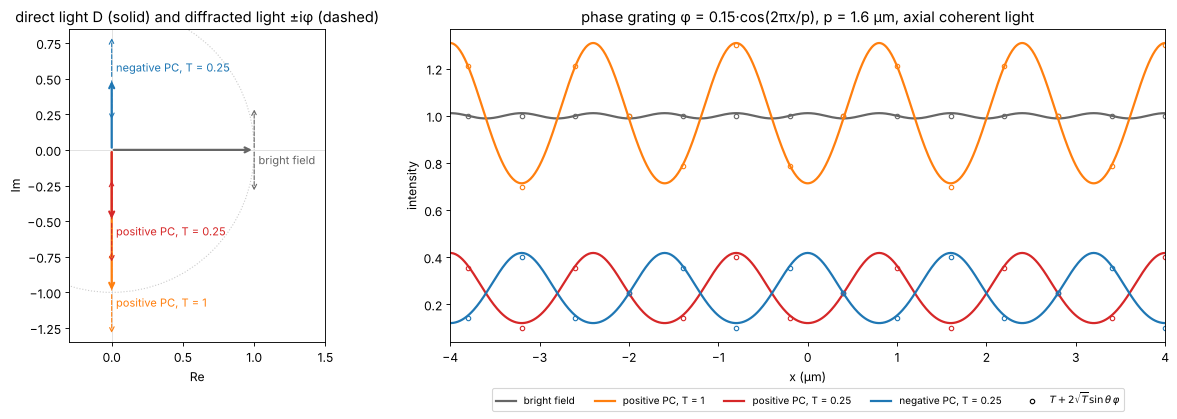

In [2]:
p = L/16
eps = 0.15
phi_g = eps*np.cos(2*np.pi*X/p)
dot = 0.03                             # radius of the phase plate in NA units
cases = [("bright field", 0.0, 1.0),
         ("positive PC, T = 1", -np.pi/2, 1.0),
         ("positive PC, T = 0.25", -np.pi/2, 0.25),
         ("negative PC, T = 0.25", np.pi/2, 0.25)]
fig, axes = plt.subplots(1, 2, figsize=(16, 5.4), gridspec_kw=dict(width_ratios=[1, 1.6]))
ax = axes[0]
colors = ["0.4", "tab:orange", "tab:red", "tab:blue"]
for (name, th, T), c in zip(cases, colors):
    D = np.sqrt(T)*np.exp(1j*th)
    ax.annotate("", xy=(D.real, D.imag), xytext=(0, 0),
                arrowprops=dict(arrowstyle="->", color=c, lw=2))
    for sgn in (1, -1):
        tip = D + 1j*sgn*0.3
        ax.annotate("", xy=(tip.real, tip.imag), xytext=(D.real, D.imag),
                    arrowprops=dict(arrowstyle="->", color=c, lw=1, ls="--"))
    ax.text(D.real + 0.03, D.imag - 0.1 if th <= 0 else D.imag + 0.05, name, color=c, fontsize=10)
ax.add_patch(Circle((0, 0), 1, fill=False, color="0.8", ls=":"))
ax.set_xlim(-0.3, 1.5); ax.set_ylim(-1.35, 0.85); ax.set_aspect("equal")
ax.axhline(0, color="0.8", lw=0.5); ax.axvline(0, color="0.8", lw=0.5)
ax.set_xlabel("Re"); ax.set_ylabel("Im")
ax.set_title("direct light D (solid) and diffracted light ±iφ (dashed)")

ax = axes[1]
for (name, th, T), c in zip(cases, colors):
    if th == 0:
        P = mic.pupil(x, y, wl, NA)
    else:
        P = mic.pupil(x, y, wl, NA, mask=mic.phase_ring(x, y, wl, 0.0, dot, phase=th, transmission=T))
    I = mic.abbe_image(np.exp(1j*phi_g), x, y, wl, NA, P=P)
    xf, If = fine(I[N//2])
    ax.plot(xf, If, color=c, lw=2, label=name)
    ax.plot(x[::6], (T + 2*np.sqrt(T)*np.sin(th)*phi_g[N//2])[::6], "o", color=c, ms=4, mfc="none")
ax.plot([], [], "ko", mfc="none", ms=4, label=r"$T + 2\sqrt{T}\sin\theta\,\varphi$")
ax.set_xlim(-4, 4); ax.set_xlabel("x (µm)"); ax.set_ylabel("intensity")
ax.set_title(f"phase grating φ = {eps}·cos(2πx/p), p = {p:.1f} µm, axial coherent light")
ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.13), fontsize=9, ncol=5)
plt.tight_layout()

Bright field shows only the faint second harmonic from $\varphi^2$; the
phase plate turns the grating into an intensity grating whose contrast
matches the linear formula (the small deviation is the $\varphi^2$ term,
here 0.02).

## 2. The phase contrast microscope: annulus, ring, halo and shade-off

A point source would make the image dim and coherent. A real phase
contrast microscope uses an **annular aperture** in the condenser
(here $\mathrm{NA}_c$ = 0.38 to 0.45, close to a Ph2 annulus for a 40×
objective) and a **phase ring** in the objective's back focal plane where
the annulus is imaged: all the direct light passes the ring, and most of
the diffracted light misses it. But not all: diffracted light at small
angles, i.e. **low spatial frequencies**, also falls onto the ring and is
treated like direct light. Large uniform structures therefore lose their
contrast towards their centre (**shade-off**), and their edges are
surrounded by a bright **halo** in positive phase contrast.

The weak object phase transfer function (`weak_object_transfer()`,
relative to the background $T$) shows this directly. Ideally it would be
flat at $-2/\sqrt{T} = -4$ (section 1); it drops to zero at $f = 0$ over a
band of about the ring width $\Delta\mathrm{NA}/\lambda$, and at high
frequencies it falls off between $(\mathrm{NA} - \mathrm{NA}_c)/\lambda$ and
$(\mathrm{NA} + \mathrm{NA}_c)/\lambda$, where the diffracted light of more
and more of the annulus leaves the pupil. Phase contrast is a high-pass filter for the
phase, and the halo is the ringing of this filter, about
$\lambda/\Delta\mathrm{NA}$ wide. The object below is a large flat cell
body (a disk of 12 µm diameter with $\varphi = 0.4$ rad) next to small
granules.

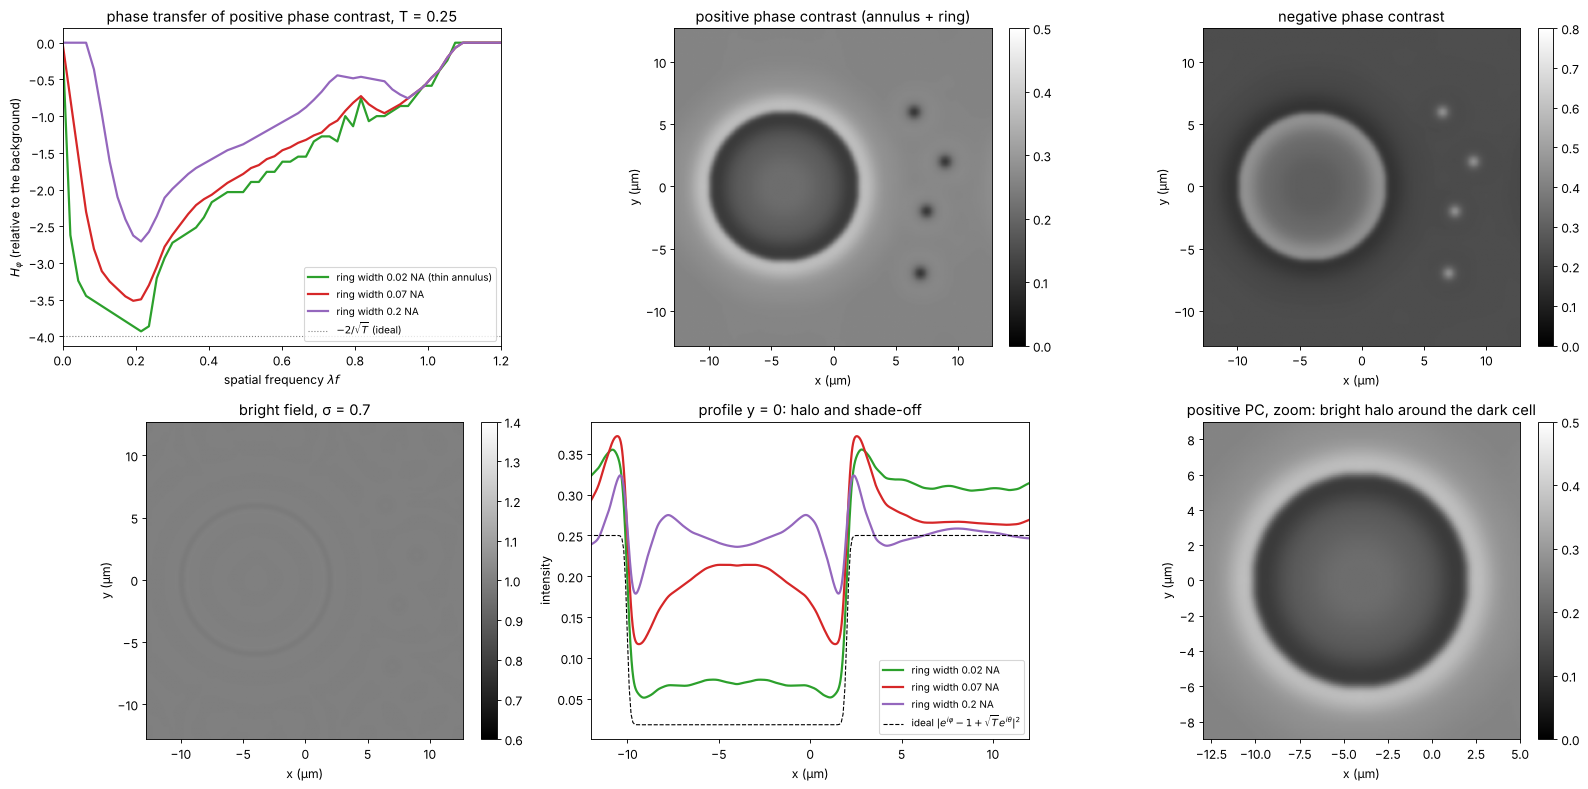

In [3]:
NA_in, NA_out = 0.38, 0.45
src_annulus = mic.source_points(x, y, wl, NA_out, NA_inner=NA_in)


def pc_pupil(width=None, phase=-np.pi/2, T=0.25):
    # ring centred on the annulus, `width` in NA units (default: the annulus itself)
    mid, half = (NA_in + NA_out)/2, ((NA_out - NA_in) if width is None else width)/2
    return mic.pupil(x, y, wl, NA, mask=mic.phase_ring(x, y, wl, mid - half, mid + half,
                                                      phase=phase, transmission=T))


disk = 0.4*smooth((np.hypot(X + 4, Y) < 6).astype(float))
for (x0, y0) in [(6.5, 6), (7.5, -2), (7, -7), (9, 2)]:
    disk += 0.3*np.exp(-((X - x0)**2 + (Y - y0)**2)/(2*0.3**2))
t_disk = np.exp(1j*disk)

fig, axes = plt.subplots(2, 3, figsize=(20, 10))
f_r = K_x[0]/(2*np.pi)*wl              # spatial frequency in NA units (lambda f)
pos = f_r >= 0
ax = axes[0, 0]
widths = [0.02, 0.07, 0.2]
wcolors = ["tab:green", "tab:red", "tab:purple"]
for wdt, c in zip(widths, wcolors):
    src = mic.source_points(x, y, wl, (NA_in + NA_out)/2 + 0.01, NA_inner=(NA_in + NA_out)/2 - 0.01) \
        if wdt < 0.05 else src_annulus
    H_a, H_phi = mic.weak_object_transfer(x, y, wl, NA, source=src, P=pc_pupil(wdt))
    ax.plot(f_r[pos], np.real(H_phi[N//2, pos]), color=c, lw=2,
            label=f"ring width {wdt:g} NA" + (" (thin annulus)" if wdt < 0.05 else ""))
ax.axhline(-2/np.sqrt(0.25), color="0.5", ls=":", lw=1, label=r"$-2/\sqrt{T}$ (ideal)")
ax.set_xlim(0, 1.2); ax.set_xlabel(r"spatial frequency $\lambda f$")
ax.set_ylabel(r"$H_\varphi$ (relative to the background)")
ax.set_title("phase transfer of positive phase contrast, T = 0.25")
ax.legend(fontsize=9, loc="lower right")

I_bf = mic.abbe_image(t_disk, x, y, wl, NA, source=mic.source_points(x, y, wl, 0.45, step=2))
I_pos = mic.abbe_image(t_disk, x, y, wl, NA, source=src_annulus, P=pc_pupil())
I_neg = mic.abbe_image(t_disk, x, y, wl, NA, source=src_annulus, P=pc_pupil(phase=np.pi/2))
show(axes[0, 1], I_pos, "positive phase contrast (annulus + ring)", vmin=0, vmax=0.5)
show(axes[0, 2], I_neg, "negative phase contrast", vmin=0, vmax=0.8)
show(axes[1, 0], I_bf, "bright field, σ = 0.7", vmin=0.6, vmax=1.4)
ax = axes[1, 1]
for wdt, c in zip(widths, wcolors):
    src = mic.source_points(x, y, wl, (NA_in + NA_out)/2 + 0.01, NA_inner=(NA_in + NA_out)/2 - 0.01) \
        if wdt < 0.05 else src_annulus
    I = mic.abbe_image(t_disk, x, y, wl, NA, source=src, P=pc_pupil(wdt))
    ax.plot(*fine(I[N//2]), color=c, lw=2, label=f"ring width {wdt:g} NA")
ax.plot(x, np.abs(np.exp(1j*disk[N//2]) - 1 - 0.5j)**2, "k--", lw=1,
        label=r"ideal $|e^{i\varphi} - 1 + \sqrt{T}e^{i\theta}|^2$")
ax.set_xlabel("x (µm)"); ax.set_ylabel("intensity"); ax.set_xlim(-12, 12)
ax.set_title("profile y = 0: halo and shade-off"); ax.legend(fontsize=9, loc="lower right")
ax = axes[1, 2]
show(ax, I_pos[np.ix_(np.abs(y) < 9, np.abs(x + 4) < 9)], "positive PC, zoom: bright halo around "
     "the dark cell", ext=(-13, 5, -9, 9), vmin=0, vmax=0.5)
for a in list(axes[0, 1:]) + [axes[1, 0], axes[1, 2]]:
    a.set_xlabel("x (µm)"); a.set_ylabel("y (µm)")
plt.tight_layout()

The ideal (dashed) is the image with an infinitely thin ring, where all
diffracted light misses the ring (section 3 explains the formula; for this
disk of 0.4 rad the linear $T - 2\sqrt{T}\varphi$ would already be
negative). The thinner the ring, the closer the image comes to it, and the narrower the band of lost low frequencies;
but a thin ring needs a thin annulus and thus little light, and a ring of
0.02 NA is hard to make and align. Commercial objectives are a compromise
like the 0.07 NA ring. Small structures (the granules, the cell edge) are
rendered faithfully, large flat areas fade towards the background, and
every edge carries a halo of opposite sign. Apodized phase contrast
(Otaki 2000) adds weakly absorbing rings on both sides of the phase ring
to smooth the cutoff of the high-pass filter and so reduce the halo.

## 3. Strong phase objects: when phase contrast stops being linear

The linear formula holds for $|\varphi| \ll 1$. For a small object of
phase $\varphi$ the direct light still comes mostly from the background,
and the field in the object is $e^{i\varphi} - 1 + \sqrt{T}e^{i\theta}$
(object wave minus the unshifted background plus the shifted one):

$$I(\varphi) = |e^{i\varphi} - 1 + \sqrt{T}e^{i\theta}|^2 ,$$

which oscillates with $\varphi$: in positive phase contrast with
$T = 0.25$ the object is darkest at $\varphi \approx 0.5$ rad and turns
**brighter** than the background beyond $\varphi \approx 1$ rad (contrast
reversal). Thick cells, or cells in a medium of very different index,
can therefore show inverted regions. Markers: centre intensity of
simulated disks of 3 µm diameter (annulus and ring as above).

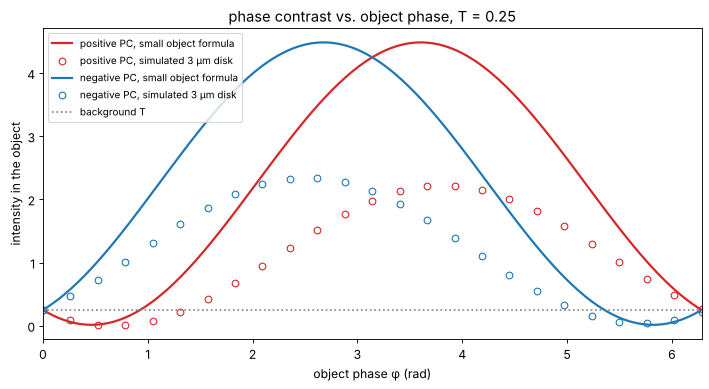

In [4]:
phis = np.linspace(0, 2*np.pi, 25)
d_small = smooth((np.hypot(X, Y) < 1.5).astype(float), 0.1)
fig, ax = plt.subplots(figsize=(9, 5))
phis_f = np.linspace(0, 2*np.pi, 300)
for th, name, c in [(-np.pi/2, "positive", "tab:red"), (np.pi/2, "negative", "tab:blue")]:
    ax.plot(phis_f, np.abs(np.exp(1j*phis_f) - 1 + 0.5*np.exp(1j*th))**2, color=c, lw=2,
            label=f"{name} PC, small object formula")
    P = pc_pupil(phase=th)
    I_c = [mic.abbe_image(np.exp(1j*ph*d_small), x, y, wl, NA, source=src_annulus, P=P)[N//2, N//2]
           for ph in phis]
    ax.plot(phis, I_c, "o", color=c, mfc="none", label=f"{name} PC, simulated 3 µm disk")
ax.axhline(0.25, color="0.5", ls=":", label="background T")
ax.set_xlabel("object phase φ (rad)"); ax.set_ylabel("intensity in the object")
ax.set_xlim(0, 2*np.pi); ax.legend(fontsize=9, loc="upper left")
ax.set_title("phase contrast vs. object phase, T = 0.25")
plt.tight_layout()

The simulated disks follow the trend of the formula but not its values:
the disk is only a few resolution elements wide, so part of its low
frequency content passes the ring (shade-off) and its own direct light
is not negligible. The qualitative message holds: phase contrast is a
**qualitative** method, linear only for $\varphi \lesssim 0.5$ rad.

## 4. Nomarski DIC

In DIC the light is linearly polarized at 45° to a Nomarski (modified
Wollaston) prism in the condenser, which splits it into two orthogonally
polarized beams sheared laterally by $s$, below the resolution limit. A
second prism behind the objective recombines them, and its lateral
position sets the **bias** retardation $\beta$; an analyzer crossed with
the polarizer makes the two images interfere. With a matching condenser
prism every source point sees the same bias, and the image is the
partially coherent image of the effective object (`dic_object()`)

$$t_\mathrm{DIC}(\mathbf{r}) = \tfrac12\left[t(\mathbf{r} + \mathbf{s}/2)\,e^{i\beta/2} - t(\mathbf{r} - \mathbf{s}/2)\,e^{-i\beta/2}\right].$$

For a phase object $t = e^{i\varphi}$ and a small shear,
$I \approx \sin^2(\beta/2) + \tfrac12\sin\beta\;\mathbf{s}\cdot\nabla\varphi$:

- $\beta = 0$ (extinction): a dark background, and only
  $(\mathbf{s}\cdot\nabla\varphi)^2/4$: edges light up on both sides, like dark field,
- $\beta = \pi/2$: the largest linear response, a grey background and the
  **shadow cast relief** look, bright on one side of a cell and dark on the
  other,
- only gradients along the shear are seen: a rim parallel to the shear is
  invisible, so users rotate the specimen.

The simulation uses a condenser of $\sigma = 0.7$, a shear of 0.15 µm along
45° and the cells.

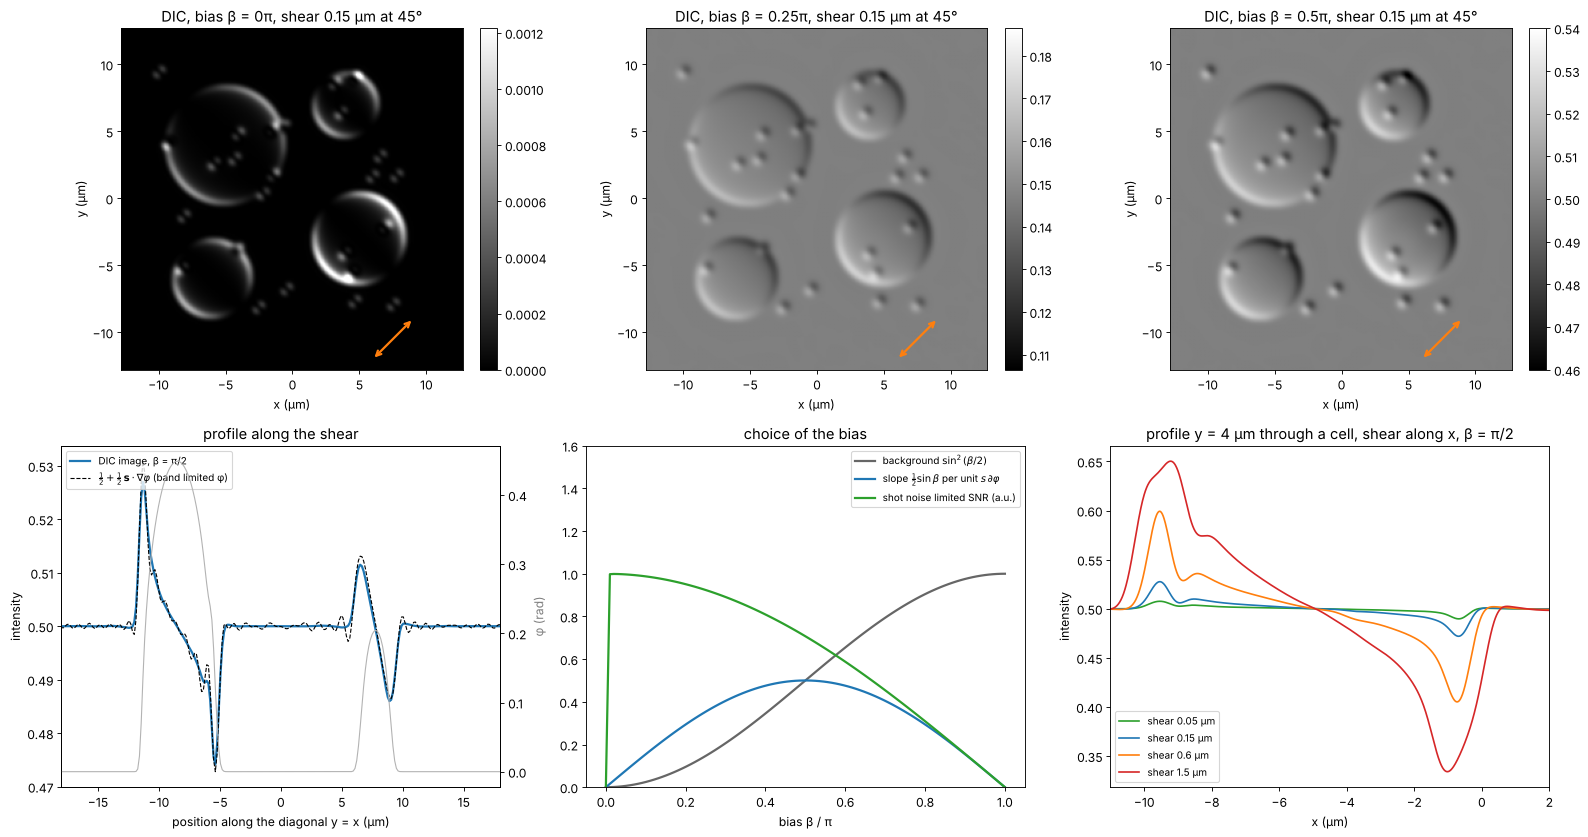

In [5]:
src_dic = mic.source_points(x, y, wl, 0.7*NA, step=2)
shear, angle = 0.15, np.pi/4
t_cells = np.exp(1j*phi_cells)
biases = [0.0, np.pi/4, np.pi/2]
fig, axes = plt.subplots(2, 3, figsize=(20, 10.6))
for j, b in enumerate(biases):
    I = mic.abbe_image(mic.dic_object(t_cells, x, y, shear, b, angle), x, y, wl, NA, source=src_dic)
    lim = (0, np.percentile(I, 99.9)) if b == 0 else (np.sin(b/2)**2 - 0.04, np.sin(b/2)**2 + 0.04)
    show(axes[0, j], I, f"DIC, bias β = {b/np.pi:g}π, shear {shear} µm at 45°", vmin=lim[0], vmax=lim[1])
    axes[0, j].annotate("", xy=(9, -9), xytext=(6, -12),
                        arrowprops=dict(arrowstyle="<->", color="tab:orange", lw=2))
# linear prediction vs. simulation, profile along the shear direction
b = np.pi/2
I = mic.abbe_image(mic.dic_object(t_cells, x, y, shear, b, angle), x, y, wl, NA, source=src_dic)
gy, gx = np.gradient(phi_cells, dx)
# the gradient seen through the objective: the phase band limited by the pupil
phi_bl = np.real(inv_FT(FT(phi_cells)*(np.hypot(K_x, K_y) <= k0*NA)))
gy_bl, gx_bl = np.gradient(phi_bl, dx)
I_lin = np.sin(b/2)**2 + 0.5*np.sin(b)*shear*(np.cos(angle)*gx_bl + np.sin(angle)*gy_bl)
ax = axes[1, 0]
idx = np.arange(N)
diag = (idx, idx)                      # the diagonal y = x, along the shear
s_diag = np.sqrt(2)*x
ax.plot(s_diag, I[diag], color="tab:blue", lw=2, label="DIC image, β = π/2")
ax.plot(s_diag, I_lin[diag], "k--", lw=1, label=r"$\frac{1}{2} + \frac{1}{2}\,\mathbf{s}\cdot\nabla\varphi$ (band limited φ)")
ax2 = ax.twinx()
ax2.plot(s_diag, phi_cells[diag], color="0.7", lw=1)
ax2.set_ylabel("φ (rad)", color="0.5")
ax.set_xlabel("position along the diagonal y = x (µm)"); ax.set_ylabel("intensity")
ax.set_title("profile along the shear"); ax.legend(fontsize=9, loc="upper left")
ax.set_xlim(-18, 18)

# bias: background and linear signal
ax = axes[1, 1]
bb = np.linspace(0, np.pi, 100)
ax.plot(bb/np.pi, np.sin(bb/2)**2, color="0.4", lw=2, label=r"background $\sin^2(\beta/2)$")
ax.plot(bb/np.pi, 0.5*np.sin(bb), color="tab:blue", lw=2, label=r"slope $\frac{1}{2}\sin\beta$ per unit $s\,\partial\varphi$")
ax.plot(bb/np.pi, 0.5*np.sin(bb)/np.sqrt(np.sin(bb/2)**2 + 1e-6), color="tab:green", lw=2,
        label="shot noise limited SNR (a.u.)")
ax.set_xlabel("bias β / π"); ax.set_ylim(0, 1.6); ax.legend(fontsize=9, loc="upper right")
ax.set_title("choice of the bias")

# shear: small vs. large
ax = axes[1, 2]
for s_, c in zip([0.05, 0.15, 0.6, 1.5], ["tab:green", "tab:blue", "tab:orange", "tab:red"]):
    I = mic.abbe_image(mic.dic_object(t_cells, x, y, s_, np.pi/2, 0.0), x, y, wl, NA, source=src_dic)
    row = np.argmin(np.abs(y - 4))
    ax.plot(*fine(I[row]), color=c, lw=1.5, label=f"shear {s_} µm")
ax.set_xlim(-11, 2); ax.set_xlabel("x (µm)"); ax.set_ylabel("intensity")
ax.set_title("profile y = 4 µm through a cell, shear along x, β = π/2")
ax.legend(fontsize=9, loc="lower left")
for a in axes[0]:
    a.set_xlabel("x (µm)"); a.set_ylabel("y (µm)")
plt.tight_layout()

At $\beta = \pi/2$ the image follows the linear gradient formula wherever
the gradient is resolved; at the steep cell rims the band limited
gradient is what the objective can transmit. The signal per photon (the
shot noise limited SNR) grows towards small bias, which is why
microscopists use $\beta$ well below $\pi/2$ for faint structures, at the
price of nonlinearity. A shear much below the resolution limit only
lowers the signal ($\propto s$); a shear above it splits the image into
a visible double image.

## 5. Why DIC needs a condenser prism

Without the condenser prism, the two polarizations of each source point
still pass the object, but the plane wave from the direction
$\mathbf{k}_s$ reaches the two sheared copies with the phase difference
$\mathbf{k}_s\cdot\mathbf{s}$. The bias then varies over the condenser
aperture, $\beta(\mathbf{k}_s) = \beta + \mathbf{k}_s\cdot\mathbf{s}$, and
the images of the different source points carry different contrast. The
Nomarski prism in the condenser is built to cancel exactly this term for
every source point (its interference plane is imaged onto the objective's
prism). Simulated below: every source point imaged separately with its
own bias, for a large shear of 0.5 µm (where the effect shows clearly) and
a full condenser.

std of the image (contrast): with prism 0.0197, without 0.0021; bias spread over the condenser ±3.34 rad


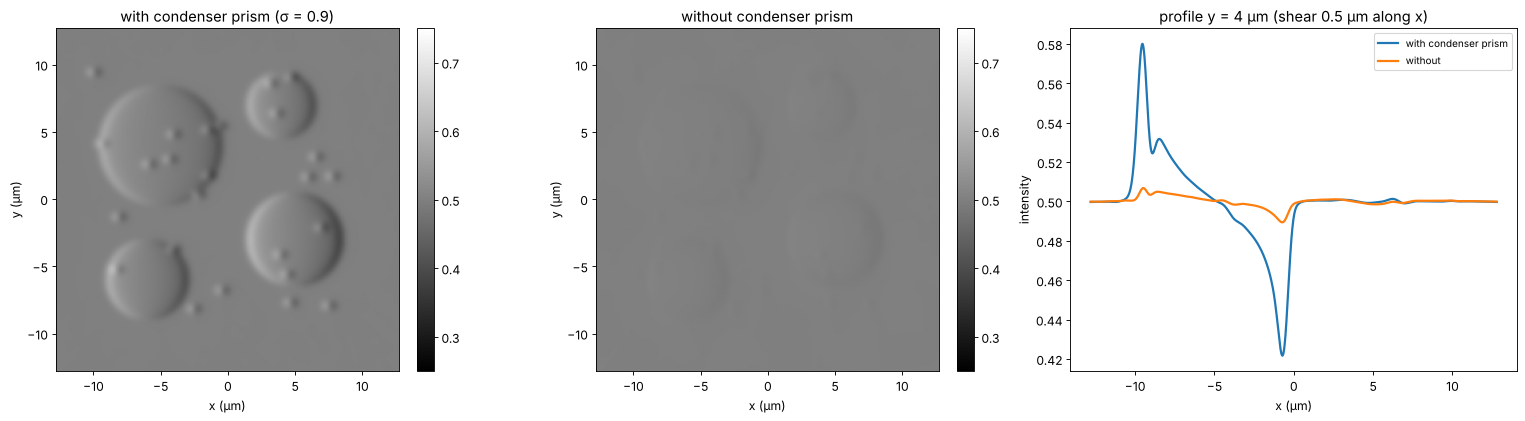

In [6]:
def dic_uncompensated(t, shear, bias, angle, source):
    k_x, k_y, w = source
    s_vec = shear*np.array([np.cos(angle), np.sin(angle)])
    I = np.zeros((N, N))
    for kx, ky, wi in zip(k_x, k_y, w):
        b_s = bias + kx*s_vec[0] + ky*s_vec[1]
        I += wi*mic.abbe_image(mic.dic_object(t, x, y, shear, b_s, angle), x, y, wl, NA,
                               source=(np.array([kx]), np.array([ky]), np.ones(1)))
    return I


s_big = 0.5
src_full = mic.source_points(x, y, wl, 0.9*NA, step=4)
I_comp = mic.abbe_image(mic.dic_object(t_cells, x, y, s_big, np.pi/2, 0.0), x, y, wl, NA, source=src_full)
I_unc = dic_uncompensated(t_cells, s_big, np.pi/2, 0.0, src_full)
fig, axes = plt.subplots(1, 3, figsize=(20, 5.4))
show(axes[0], I_comp, "with condenser prism (σ = 0.9)", vmin=0.25, vmax=0.75)
show(axes[1], I_unc, "without condenser prism", vmin=0.25, vmax=0.75)
row = np.argmin(np.abs(y - 4))
axes[2].plot(*fine(I_comp[row]), lw=2, label="with condenser prism")
axes[2].plot(*fine(I_unc[row]), lw=2, label="without")
axes[2].set_xlabel("x (µm)"); axes[2].set_ylabel("intensity"); axes[2].legend(fontsize=9)
axes[2].set_title(f"profile y = 4 µm (shear {s_big} µm along x)")
for a in axes[:2]:
    a.set_xlabel("x (µm)"); a.set_ylabel("y (µm)")
plt.tight_layout()
print(f"std of the image (contrast): with prism {np.std(I_comp):.4f}, without {np.std(I_unc):.4f}; "
      f"bias spread over the condenser ±{k0*0.9*NA*s_big:.2f} rad")

Without the condenser prism the bias varies by ±3.3 rad over the
condenser, the source points with opposite contrast cancel, and the relief
contrast drops tenfold; closing the condenser aperture would restore
it at the price of resolution and depth discrimination. DIC owes its
thin optical sections precisely to the wide condenser aperture it can
use.

## 6. Phase contrast vs. DIC

| | Zernike phase contrast | Nomarski DIC |
|---|---|---|
| image | $\approx T - 2\sqrt{T}\varphi$: the phase itself, high-pass filtered | $\approx \sin^2(\beta/2) + \frac12\sin\beta\,\mathbf{s}\cdot\nabla\varphi$: the phase gradient along the shear |
| artifacts | halo and shade-off (ring width), contrast reversal above ≈ 1 rad | relief only along the shear, no halo |
| condenser | annulus matched to the ring, fixed $\sigma$ | full aperture, thin optical sections |
| hardware | phase objectives with a ring, annuli | polarizers, two Nomarski prisms, strain free optics |
| samples | thin cells in culture, plastic dishes | thicker specimens; no birefringent dishes |

Neither method is quantitative. For the phase in radians, see digital
holography ([27](27_holographic_microscopy.ipynb)), the TIE
([29](29_TIE.ipynb)) or Fourier ptychography
([55](55_fourier_ptychography.ipynb)); confocal microscopy
([54](54_confocal_microscopy.ipynb)) takes up the optical sectioning
mentioned above.

In [7]:
print(f"run time {time.time() - t_start:.0f} s")

run time 79 s


## References

- F. Zernike, "Phase contrast, a new method for the microscopic observation of transparent objects", Physica 9, 686-698 (1942).
- F. Zernike, "How I discovered phase contrast", Science 121, 345-349 (1955).
- A. H. Bennett, H. Osterberg, H. Jupnik and O. W. Richards, *Phase Microscopy: Principles and Applications*, Wiley (1951).
- M. Born and E. Wolf, *Principles of Optics*, 7th ed., Cambridge University Press (1999), section 8.6.
- Y. Otaki, "Artifact halo reduction in phase contrast microscopy using apodization", Opt. Rev. 7, 119-122 (2000).
- Z. Yin, T. Kanade and M. Chen, "Understanding the phase contrast optics to restore artifact-free microscopy images for segmentation", Med. Image Anal. 16, 1047-1062 (2012).
- G. Nomarski, "Microinterféromètre différentiel à ondes polarisées", J. Phys. Radium 16, 9S-13S (1955).
- R. D. Allen, G. B. David and G. Nomarski, "The Zeiss-Nomarski differential interference equipment for transmitted-light microscopy", Z. wiss. Mikrosk. 69, 193-221 (1969).
- C. Preza, D. L. Snyder and J.-A. Conchello, "Theoretical development and experimental evaluation of imaging models for differential-interference-contrast microscopy", J. Opt. Soc. Am. A 16, 2185-2199 (1999).
- J. Mertz, *Introduction to Optical Microscopy*, 2nd ed., Cambridge University Press (2019).